# Wildfire Dataset Integration and Preprocessing

The 25 .csv files obtained from the Texas A&M Forest Service contained 55 shared features, along with one additional raster derived feature unique to each file. These files were combined into a single dataset, retaining the shared features and incorporating all 25 unique raster derived features.

In [1]:
import pandas as pd
import glob
import os
import missingno as msno
import matplotlib.pyplot as plt

In [2]:
# Choose random .csv file
df1 = pd.read_csv(
    "Challenges to Fire Operations/WHP_pt.csv",
    encoding="cp1252"
    )

/var/folders/6t/2jhf471114v5c23mm3_tc1_r0000gn/T/ipykernel_30904/1732141508.py:2: DtypeWarning: Columns (15: IrwinID) have mixed types. Specify dtype option on import or set low_memory=False.
  df1 = pd.read_csv(


In [3]:
# Choose second random .csv file
df2 = pd.read_csv(
    "EMS_pt.csv",
    encoding="cp1252"
    )

/var/folders/6t/2jhf471114v5c23mm3_tc1_r0000gn/T/ipykernel_30904/1338414026.py:2: DtypeWarning: Columns (15: IrwinID) have mixed types. Specify dtype option on import or set low_memory=False.
  df2 = pd.read_csv(


In [4]:
# First file shape
df1.shape

(275363, 56)

In [5]:
# First file head
df1.head()

,Agency,ID_Incident,StartDate,Contained,Controlled,County,FireName,Lat,Long,acres,...,slope_deg,aspect_deg,soil_clay_pct,soil_sand_pct,soil_bulk_density,soil_filled_from_neighbors,northness,eastness,static_missing,WHP_pt_1
0,FD,AEA0A967-E4C9-45C3-BD5F-0000D3C0A9DD,2011/07/17 00:00:00,NaN,NaN,Wichita,Rekindle Krohn Rd,34.091480,-98.898642,0.0,...,1.387681,344.620389,22.2,26.1,1.56,0,0.964190,-0.265213,0,1.0
1,FD,5E7D8AA7-872F-4C28-849C-0001031ACCD5,2020/04/08 12:59:00,2020/04/08 13:16:00,2020/04/08 13:52:00,Aransas,190,28.057600,-97.104200,0.1,...,0.277841,26.845850,16.0,61.8,1.36,0,0.892225,0.451592,0,4.0
2,FD,A9DBA206-FB1E-4061-9500-0001FC0A547D,2009/04/25 00:00:00,NaN,NaN,Bee,Grass Fire,28.413202,-97.723735,0.5,...,1.350076,212.858923,28.4,49.3,1.55,0,-0.840009,-0.542572,0,4.0
3,FD,E47D6494-9964-4F0A-B4F8-0002615830C7,2008/01/29 00:00:00,NaN,NaN,Bell,7000 Stillman Valley,30.934168,-97.716991,20.0,...,3.014784,233.879152,40.7,17.7,1.58,0,-0.589490,-0.807775,0,7.0
4,FD,7CD8FF55-5E90-450B-8687-0002A206891B,2008/06/17 00:00:00,NaN,NaN,Mills,Stone Creek #3,31.557167,-98.665667,1.0,...,0.606783,172.564670,34.1,26.8,1.53,0,-0.991592,0.129407,0,4.0


In [6]:
# Second file shape
df2.shape

(275363, 56)

In [7]:
# Second file head
df2.head()

,Agency,ID_Incident,StartDate,Contained,Controlled,County,FireName,Lat,Long,acres,...,slope_deg,aspect_deg,soil_clay_pct,soil_sand_pct,soil_bulk_density,soil_filled_from_neighbors,northness,eastness,static_missing,EMS_pt_1
0,FD,AEA0A967-E4C9-45C3-BD5F-0000D3C0A9DD,2011/07/17 00:00:00,NaN,NaN,Wichita,Rekindle Krohn Rd,34.091480,-98.898642,0.0,...,1.387681,344.620389,22.2,26.1,1.56,0,0.964190,-0.265213,0,9410.0
1,FD,5E7D8AA7-872F-4C28-849C-0001031ACCD5,2020/04/08 12:59:00,2020/04/08 13:16:00,2020/04/08 13:52:00,Aransas,190,28.057600,-97.104200,0.1,...,0.277841,26.845850,16.0,61.8,1.36,0,0.892225,0.451592,0,6307.0
2,FD,A9DBA206-FB1E-4061-9500-0001FC0A547D,2009/04/25 00:00:00,NaN,NaN,Bee,Grass Fire,28.413202,-97.723735,0.5,...,1.350076,212.858923,28.4,49.3,1.55,0,-0.840009,-0.542572,0,9410.0
3,FD,E47D6494-9964-4F0A-B4F8-0002615830C7,2008/01/29 00:00:00,NaN,NaN,Bell,7000 Stillman Valley,30.934168,-97.716991,20.0,...,3.014784,233.879152,40.7,17.7,1.58,0,-0.589490,-0.807775,0,1102.0
4,FD,7CD8FF55-5E90-450B-8687-0002A206891B,2008/06/17 00:00:00,NaN,NaN,Mills,Stone Creek #3,31.557167,-98.665667,1.0,...,0.606783,172.564670,34.1,26.8,1.53,0,-0.991592,0.129407,0,9411.0


In [8]:
# Check if ID is the same and in the same order for both datasets
print(
    df1["ID_Incident"].equals(df2["ID_Incident"])
)

True


In [9]:
print("df1 rows:", len(df1))
print("df2 rows:", len(df2))

print("df1 unique IDs:", df1["ID_Incident"].nunique())
print("df2 unique IDs:", df2["ID_Incident"].nunique())

df1 rows: 275363
df2 rows: 275363
df1 unique IDs: 275363
df2 unique IDs: 275363


In [10]:
# Find columns that exist in both datasets
common_columns = set(df1.columns) & set(df2.columns)

print("Common columns:", len(common_columns))

# Find columns unique to each dataset
print("Only in df1:", set(df1.columns) - set(df2.columns))
print("Only in df2:", set(df2.columns) - set(df1.columns))

Common columns: 55
Only in df1: {'WHP_pt_1'}
Only in df2: {'EMS_pt_1'}


In [11]:
# Combine just these two datasets as a test
combined = pd.concat(
    [df1, df2[["EMS_pt_1"]]],
    axis=1
)

In [12]:
print(combined.shape)

(275363, 57)


In [13]:
combined.iloc[:, -5:].head()

,northness,eastness,static_missing,WHP_pt_1,EMS_pt_1
0,0.964190,-0.265213,0,1.0,9410.0
1,0.892225,0.451592,0,4.0,6307.0
2,-0.840009,-0.542572,0,4.0,9410.0
3,-0.589490,-0.807775,0,7.0,1102.0
4,-0.991592,0.129407,0,4.0,9411.0


In [14]:
# All .csv files
files = glob.glob("**/*.csv", recursive=True)

print("Number of CSV files:", len(files))

for file in files:
    print(file)

Number of CSV files: 25
EMS_pt.csv
Wildfire Risk/HU_impact_pt.csv
Wildfire Risk/SELB_pt.csv
Wildfire Risk/HU_risk_pt.csv
Wildfire Risk/funct_WUI_pt.csv
Wildfire Risk/HU_den_pt.csv
Challenges to Fire Operations/xmanualctrl_4_pt.csv
Challenges to Fire Operations/WHP_pt.csv
Challenges to Fire Operations/xmechctrl_8_pt.csv
Challenges to Fire Operations/xextreme_11_pt.csv
Challenges to Fire Operations/SDI_pt.csv
Landscape Characteristics/Slope_pt.csv
Landscape Characteristics/SurfaceFuel_pt.csv
Flame Front Characteristics/eFIS_pt.csv
Flame Front Characteristics/cFIS_pt.csv
Flame Front Characteristics/p_crown_fire_pt.csv
Flame Front Characteristics/cFL_pt.csv
Flame Front Characteristics/eFL_pt.csv
Flame Front Characteristics/eROS_pt.csv
Flame Front Characteristics/cROS_pt.csv
Ember Characteristics/EmberProd_pt.csv
Ember Characteristics/EmberLoad_pt.csv
Wildfire Hazard/WES_pt.csv
Wildfire Hazard/BP_pt.csv
Wildfire Hazard/DP_pt.csv


In [15]:
# Find all .csv files
files = glob.glob("**/*.csv", recursive=True)

# Use EMS_pt.csv as the starting file
reference_file = next(
    file for file in files if os.path.basename(file) == "EMS_pt.csv"
)

reference = pd.read_csv(reference_file, encoding="cp1252")

# Identify the 55 original/shared columns
base_columns = [
    col for col in reference.columns if col != "EMS_pt_1"
]

# Start the combined dataset
combined = reference.copy()

# Check and add the remaining 24 files
for file in files:
    if file == reference_file:
        continue

    df = pd.read_csv(file, encoding="cp1252")

    # Check that the incident IDs match in the same order
    if not reference["ID_Incident"].equals(df["ID_Incident"]):
        raise ValueError(f"Incident IDs do not match in {file}")

    # Check that all original columns are present
    if not all(col in df.columns for col in base_columns):
        raise ValueError(f"Missing original columns in {file}")

    # Check that the shared data is identical
    if not reference[base_columns].equals(df[base_columns]):
        raise ValueError(f"Original data differs in {file}")

    # Find the new raster-value column
    new_columns = [col for col in df.columns if col not in base_columns]

    if len(new_columns) != 1:
        raise ValueError(f"Expected one new column in {file}, found {new_columns}")

    feature = new_columns[0]

    if feature in combined.columns:
        raise ValueError(f"Duplicate column name: {feature}")

    # Add the raster values
    combined[feature] = df[feature]

print("All files successfully checked and combined!")
print("Final dataset shape:", combined.shape)
print("Total columns:", len(combined.columns))

/var/folders/6t/2jhf471114v5c23mm3_tc1_r0000gn/T/ipykernel_30904/268954745.py:9: DtypeWarning: Columns (15: IrwinID) have mixed types. Specify dtype option on import or set low_memory=False.
  reference = pd.read_csv(reference_file, encoding="cp1252")
/var/folders/6t/2jhf471114v5c23mm3_tc1_r0000gn/T/ipykernel_30904/268954745.py:24: DtypeWarning: Columns (15: IrwinID) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file, encoding="cp1252")


All files successfully checked and combined!
Final dataset shape: (275363, 80)
Total columns: 80


55 shared features + 25 unique features (1 feature from each dataset) = 80 total features

In [16]:
combined.to_csv("combined_all_rasters.csv", index=False)

In [17]:
check = pd.read_csv("combined_all_rasters.csv")

print(check.shape)

(275363, 80)


/var/folders/6t/2jhf471114v5c23mm3_tc1_r0000gn/T/ipykernel_30904/2041425660.py:1: DtypeWarning: Columns (15: IrwinID) have mixed types. Specify dtype option on import or set low_memory=False.
  check = pd.read_csv("combined_all_rasters.csv")


In [18]:
check.columns.tolist()

['Agency',
 'ID_Incident',
 'StartDate',
 'Contained',
 'Controlled',
 'County',
 'FireName',
 'Lat',
 'Long',
 'acres',
 'CauseGeneral',
 'CauseSpecific',
 'CauseSpecificDetail',
 'Department',
 'BadLocation',
 'IrwinID',
 'Shape',
 'bi',
 'erc',
 'pr',
 'rmax',
 'rmin',
 'tmmn',
 'tmmx',
 'vs',
 'temp_max_c',
 'temp_min_c',
 'point_county',
 'point_county_fips',
 'county_fips',
 'outside_texas',
 'county_mismatch',
 'km_from_listed_county',
 'start_date',
 'start_time_known',
 'start_hour',
 'year',
 'month',
 'day_of_year',
 'day_of_week',
 'contained_before_start',
 'zero_acres',
 'log_acres',
 'slope_deg_v1',
 'aspect_deg_v1',
 'elevation',
 'slope_deg',
 'aspect_deg',
 'soil_clay_pct',
 'soil_sand_pct',
 'soil_bulk_density',
 'soil_filled_from_neighbors',
 'northness',
 'eastness',
 'static_missing',
 'EMS_pt_1',
 'HUimpact_pt_1',
 'SELB_pt_1',
 'HUrisk_pt_1',
 'funct_wui_pt_1',
 'HUDEN_pt_1',
 'xmanualctrl_4_pt_1',
 'WHP_pt_1',
 'xmechctrl_8_pt_1',
 'xextreme_11_pt_1',
 'SDI_pt_

In [19]:
# Added features
check.iloc[:, -25:].dtypes

EMS_pt_1              float64
HUimpact_pt_1         float64
SELB_pt_1             float64
HUrisk_pt_1           float64
funct_wui_pt_1        float64
HUDEN_pt_1            float64
xmanualctrl_4_pt_1    float64
WHP_pt_1              float64
xmechctrl_8_pt_1      float64
xextreme_11_pt_1      float64
SDI_pt_1              float64
Slope_pt_1            float64
SurfaceFuel_pt_1      float64
eFIS_pt_1             float64
cFIS_pt_1             float64
p_crown_fire_pt_1     float64
cFL_pt_1              float64
eFL_pt_1              float64
eROS_pt_1             float64
cROS_pt_1             float64
EmberProd_pt_1        float64
EmberLoad_pt_1        float64
WES_pt_1              float64
bp_pt_1               float64
DP_pt_1               float64
dtype: object

In [20]:
pd.set_option("display.max_columns", None)

check.iloc[:, -25:].head()

,EMS_pt_1,HUimpact_pt_1,SELB_pt_1,HUrisk_pt_1,funct_wui_pt_1,HUDEN_pt_1,xmanualctrl_4_pt_1,WHP_pt_1,xmechctrl_8_pt_1,xextreme_11_pt_1,SDI_pt_1,Slope_pt_1,SurfaceFuel_pt_1,eFIS_pt_1,cFIS_pt_1,p_crown_fire_pt_1,cFL_pt_1,eFL_pt_1,eROS_pt_1,cROS_pt_1,EmberProd_pt_1,EmberLoad_pt_1,WES_pt_1,bp_pt_1,DP_pt_1
0,9410.0,1.0,0.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,1.0,0.0,2.0,5.0,4.0,2.0
1,6307.0,6.0,0.0,6.0,2.0,5.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,1.0,0.0,2.0,6.0,7.0,3.0
2,9410.0,5.0,0.0,5.0,1.0,3.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,1.0,0.0,1.0,4.0,5.0,2.0
3,1102.0,5.0,2.0,6.0,6.0,3.0,2.0,7.0,2.0,2.0,3.0,1.0,21.0,9.0,7.0,2.0,6.0,8.0,5.0,2.0,3.0,3.0,6.0,8.0,3.0
4,9411.0,6.0,0.0,6.0,2.0,5.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.0,1.0,0.0,2.0,5.0,6.0,2.0


All added features are categorical.

In [21]:
ranges = pd.DataFrame({
    "Minimum": check.iloc[:, -25:].min(),
    "Maximum": check.iloc[:, -25:].max()
})

ranges

,Minimum,Maximum
EMS_pt_1,0.0,12306.0
HUimpact_pt_1,1.0,7.0
SELB_pt_1,0.0,4.0
HUrisk_pt_1,1.0,7.0
funct_wui_pt_1,1.0,6.0
HUDEN_pt_1,1.0,7.0
xmanualctrl_4_pt_1,1.0,6.0
WHP_pt_1,1.0,9.0
xmechctrl_8_pt_1,1.0,6.0
xextreme_11_pt_1,1.0,6.0


EMS has a higher numerical range since it represents a detailed ecological classification system (398 different classes from dataset glossary) that distinguishes numerous vegetation, land cover, and environmental characteristics across Texas. EMS is not continuous and its numerical values are class identifiers.

In [22]:
check.iloc[:, -25:].describe()

,EMS_pt_1,HUimpact_pt_1,SELB_pt_1,HUrisk_pt_1,funct_wui_pt_1,HUDEN_pt_1,xmanualctrl_4_pt_1,WHP_pt_1,xmechctrl_8_pt_1,xextreme_11_pt_1,SDI_pt_1,Slope_pt_1,SurfaceFuel_pt_1,eFIS_pt_1,cFIS_pt_1,p_crown_fire_pt_1,cFL_pt_1,eFL_pt_1,eROS_pt_1,cROS_pt_1,EmberProd_pt_1,EmberLoad_pt_1,WES_pt_1,bp_pt_1,DP_pt_1
count,275360.000000,275215.000000,275216.000000,275216.000000,272231.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,19090.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000,275216.000000
mean,5187.896445,3.561772,0.396361,3.679579,3.354383,2.738293,2.330021,4.170619,1.658032,1.379952,1.816791,1.180902,6.615963,4.263171,3.639323,2.250445,2.839442,3.365226,2.797813,2.123082,1.097952,1.610470,4.330126,5.809124,2.470692
std,3836.678767,2.088751,0.573788,2.187515,1.770508,1.941998,1.983256,1.646471,1.220763,0.799909,0.810219,0.442892,6.332504,2.991352,2.498023,0.548245,1.743434,2.205106,1.894128,1.243994,1.158339,0.745171,1.811016,1.837238,0.673196
min,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,1107.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,3.000000,5.000000,2.000000
50%,4001.000000,5.000000,0.000000,5.000000,4.000000,2.000000,1.000000,5.000000,1.000000,1.000000,2.000000,1.000000,5.000000,5.000000,4.000000,2.000000,3.000000,4.000000,2.000000,2.000000,1.000000,1.000000,4.000000,6.000000,2.000000
75%,9307.000000,5.000000,1.000000,6.000000,4.000000,4.000000,4.000000,5.000000,2.000000,1.000000,2.000000,1.000000,9.000000,7.000000,6.000000,2.000000,5.000000,5.000000,4.000000,3.000000,2.000000,2.000000,6.000000,7.000000,3.000000
max,12306.000000,7.000000,4.000000,7.000000,6.000000,7.000000,6.000000,9.000000,6.000000,6.000000,6.000000,7.000000,23.000000,10.000000,9.000000,5.000000,8.000000,9.000000,7.000000,6.000000,4.000000,4.000000,9.000000,11.000000,6.000000


In [23]:
check.iloc[:, -25:].isnull().sum()

EMS_pt_1                   3
HUimpact_pt_1            148
SELB_pt_1                147
HUrisk_pt_1              147
funct_wui_pt_1          3132
HUDEN_pt_1               147
xmanualctrl_4_pt_1       147
WHP_pt_1                 147
xmechctrl_8_pt_1         147
xextreme_11_pt_1         147
SDI_pt_1                 147
Slope_pt_1               147
SurfaceFuel_pt_1         147
eFIS_pt_1                147
cFIS_pt_1                147
p_crown_fire_pt_1     256273
cFL_pt_1                 147
eFL_pt_1                 147
eROS_pt_1                147
cROS_pt_1                147
EmberProd_pt_1           147
EmberLoad_pt_1           147
WES_pt_1                 147
bp_pt_1                  147
DP_pt_1                  147
dtype: int64

A lot of the features have exactly 147 missing values. This shows that most missing values are not missing completely at random.

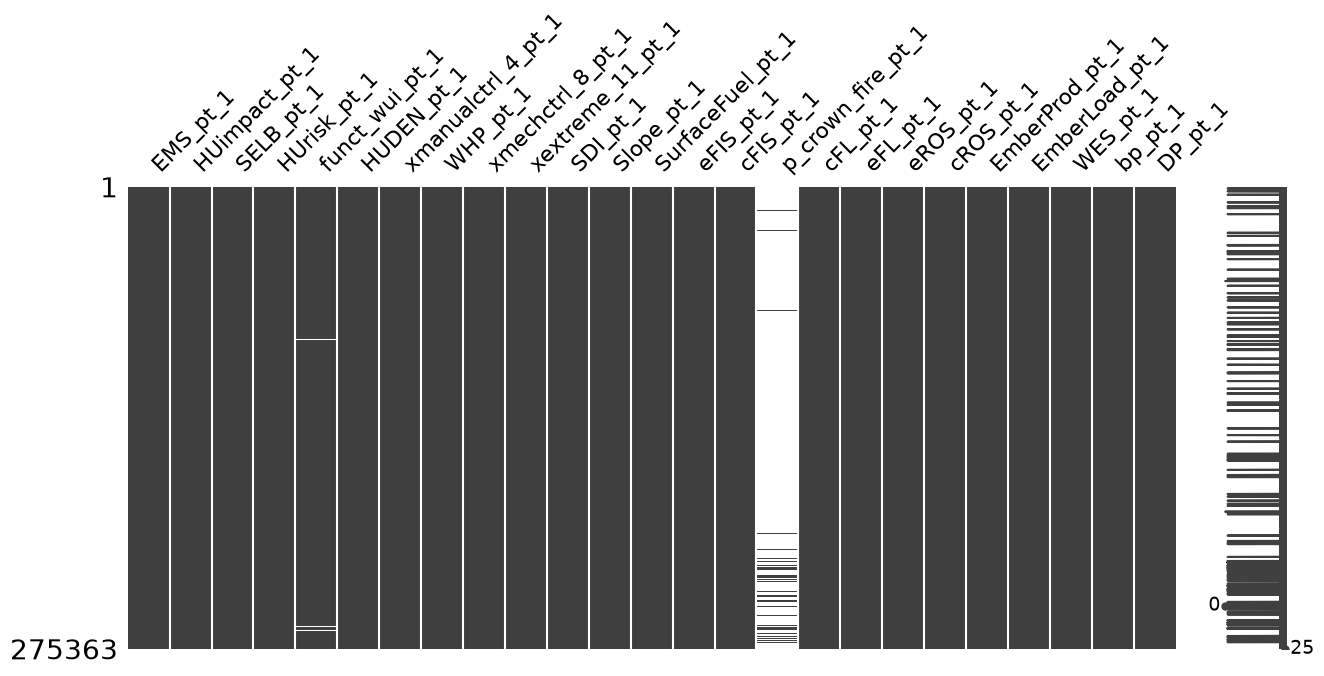

In [24]:
msno.matrix(check.iloc[:, -25:], figsize=(15, 6))
plt.show()

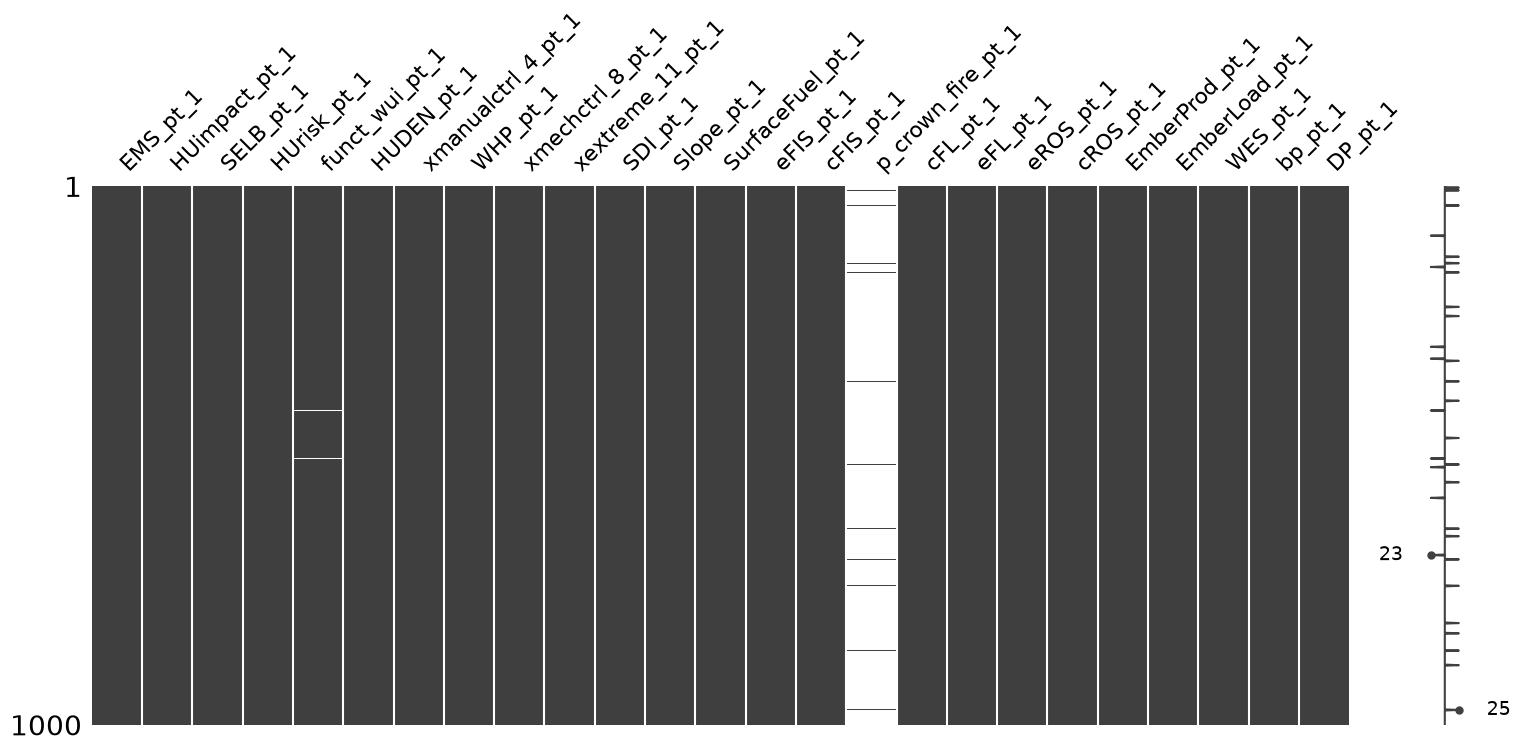

In [25]:
# Check with sample = 1000
sample = check.iloc[:1000, -25:]

msno.matrix(sample, figsize=(18, 7))
plt.show()

Dataset so large (almost 280,000 entries) that you cannot distinguish a pattern with missingno when only ~150 rows are missing. Even when taking a sample of the first 1000 entries.

In [26]:
# Group features with 147/148 missing values (22 features)
raster_columns = check.columns[-25:]

missing_counts = check[raster_columns].isnull().sum()

features_147_148 = missing_counts[missing_counts.isin([147, 148])].index.tolist()

print(features_147_148)

['HUimpact_pt_1', 'SELB_pt_1', 'HUrisk_pt_1', 'HUDEN_pt_1', 'xmanualctrl_4_pt_1', 'WHP_pt_1', 'xmechctrl_8_pt_1', 'xextreme_11_pt_1', 'SDI_pt_1', 'Slope_pt_1', 'SurfaceFuel_pt_1', 'eFIS_pt_1', 'cFIS_pt_1', 'cFL_pt_1', 'eFL_pt_1', 'eROS_pt_1', 'cROS_pt_1', 'EmberProd_pt_1', 'EmberLoad_pt_1', 'WES_pt_1', 'bp_pt_1', 'DP_pt_1']


In [27]:
missing_pattern = check[features_147_148].isnull()

missing_pattern.sum(axis=1).value_counts().sort_index()

0     275215
1          1
22       147
Name: count, dtype: int64

In [28]:
missing_pattern.sum(axis=0).sort_values(ascending=False)

HUimpact_pt_1         148
SELB_pt_1             147
bp_pt_1               147
WES_pt_1              147
EmberLoad_pt_1        147
EmberProd_pt_1        147
cROS_pt_1             147
eROS_pt_1             147
eFL_pt_1              147
cFL_pt_1              147
cFIS_pt_1             147
eFIS_pt_1             147
SurfaceFuel_pt_1      147
Slope_pt_1            147
SDI_pt_1              147
xextreme_11_pt_1      147
xmechctrl_8_pt_1      147
WHP_pt_1              147
xmanualctrl_4_pt_1    147
HUDEN_pt_1            147
HUrisk_pt_1           147
DP_pt_1               147
dtype: int64

In [29]:
# Focusing on specific fire characteristics/date/county
metadata_columns = [
    c for c in df.columns if any(
        word in c.lower() for word in ["fire", "date", "incident", "name", "county", "acres"]
    )
]

In [30]:
# Rows with the 22 features missing (only showing metadata_columns)
missing_records = check.loc[
    missing_pattern.sum(axis=1) == 22,
    metadata_columns
]

missing_records.head(20)

,ID_Incident,StartDate,County,FireName,acres,point_county,point_county_fips,county_fips,county_mismatch,km_from_listed_county,start_date,zero_acres,log_acres
1020,24C9C15B-1FA1-455F-8553-01380EF9E5CC,2011/09/18 00:00:00,Harrison,grass fire,0.5,NaN,NaN,48203,1,3.836,2011/09/18,0,0.405465
2675,0822EE08-3E2C-48C1-B695-03121CD4F79D,2011/08/28 00:00:00,Lipscomb,Col Blau,20.0,NaN,NaN,48295,1,1.120,2011/08/28,0,3.044522
4750,F52F7CA5-CD8F-4990-B47D-057EFCB4F111,2022/06/25 19:51:00,Panola,DeSoto Parish #1 &3 on Holmes rd,1.0,NaN,NaN,48365,1,0.515,2022/06/25,0,0.693147
9305,9A5E8C33-830A-4A82-B7C8-0ABEBFA95F9C,2011/05/09 00:00:00,Gaines,GRASS FIRE(MUTUAL AID),1000.0,NaN,NaN,48165,1,3.687,2011/05/09,0,6.908755
11643,30488DEE-716F-4003-92CB-0D7EC64EE8BF,2010/10/31 00:00:00,Brazoria,San Luis Pass,0.0,Brazoria,48039.0,48039,0,0.000,2010/10/31,1,0.000000
12712,D0BC3195-75D6-4F72-9589-0EBA3D6DD6C8,2008/02/26 00:00:00,Wheeler,STATE LINE ROAD,50.0,Wheeler,48483.0,48483,0,0.000,2008/02/26,0,3.931826
16314,9569DA63-A05B-4D6B-A9F6-12DA45308BC1,2012/06/29 00:00:00,Wichita,Co 1199,500.0,NaN,NaN,48485,1,1.584,2012/06/29,0,6.216606
27438,AB634765-DAD5-44FB-A315-1FEF0361C101,2009/10/31 00:00:00,Dallam,State Line Rd,45.0,NaN,NaN,48111,1,0.065,2009/10/31,0,3.828641
29275,3BE1EABF-463D-464C-A4AB-2235BBE3FCC9,2011/05/21 00:00:00,Brazoria,La Folletts beach/CR 257,1.0,Brazoria,48039.0,48039,0,0.000,2011/05/21,0,0.693147
34714,BA36F693-0BC2-42D8-A76F-2898B829609D,2011/09/17 00:00:00,Harrison,mutual aid,0.1,NaN,NaN,48203,1,0.990,2011/09/17,0,0.095310


Cannot see similarities when only checking the records with the missing 22 features.

In [31]:
# Rows missing values in 22 features
missing_records = check.loc[missing_pattern.sum(axis=1) == 22]

# Rows without missing values in those features
complete_records = check.loc[missing_pattern.sum(axis=1) == 0]

print("Missing records:", len(missing_records))
print("Complete records:", len(complete_records))

Missing records: 147
Complete records: 275215


In [32]:
# Check only rows with the missing values in the 22 features again
display(missing_records[metadata_columns].head(10))

,ID_Incident,StartDate,County,FireName,acres,point_county,point_county_fips,county_fips,county_mismatch,km_from_listed_county,start_date,zero_acres,log_acres
1020,24C9C15B-1FA1-455F-8553-01380EF9E5CC,2011/09/18 00:00:00,Harrison,grass fire,0.5,NaN,NaN,48203,1,3.836,2011/09/18,0,0.405465
2675,0822EE08-3E2C-48C1-B695-03121CD4F79D,2011/08/28 00:00:00,Lipscomb,Col Blau,20.0,NaN,NaN,48295,1,1.120,2011/08/28,0,3.044522
4750,F52F7CA5-CD8F-4990-B47D-057EFCB4F111,2022/06/25 19:51:00,Panola,DeSoto Parish #1 &3 on Holmes rd,1.0,NaN,NaN,48365,1,0.515,2022/06/25,0,0.693147
9305,9A5E8C33-830A-4A82-B7C8-0ABEBFA95F9C,2011/05/09 00:00:00,Gaines,GRASS FIRE(MUTUAL AID),1000.0,NaN,NaN,48165,1,3.687,2011/05/09,0,6.908755
11643,30488DEE-716F-4003-92CB-0D7EC64EE8BF,2010/10/31 00:00:00,Brazoria,San Luis Pass,0.0,Brazoria,48039.0,48039,0,0.000,2010/10/31,1,0.000000
12712,D0BC3195-75D6-4F72-9589-0EBA3D6DD6C8,2008/02/26 00:00:00,Wheeler,STATE LINE ROAD,50.0,Wheeler,48483.0,48483,0,0.000,2008/02/26,0,3.931826
16314,9569DA63-A05B-4D6B-A9F6-12DA45308BC1,2012/06/29 00:00:00,Wichita,Co 1199,500.0,NaN,NaN,48485,1,1.584,2012/06/29,0,6.216606
27438,AB634765-DAD5-44FB-A315-1FEF0361C101,2009/10/31 00:00:00,Dallam,State Line Rd,45.0,NaN,NaN,48111,1,0.065,2009/10/31,0,3.828641
29275,3BE1EABF-463D-464C-A4AB-2235BBE3FCC9,2011/05/21 00:00:00,Brazoria,La Folletts beach/CR 257,1.0,Brazoria,48039.0,48039,0,0.000,2011/05/21,0,0.693147
34714,BA36F693-0BC2-42D8-A76F-2898B829609D,2011/09/17 00:00:00,Harrison,mutual aid,0.1,NaN,NaN,48203,1,0.990,2011/09/17,0,0.095310


In [33]:
# Check complete records and compare with missing records
display(complete_records[metadata_columns].head(10))

,ID_Incident,StartDate,County,FireName,acres,point_county,point_county_fips,county_fips,county_mismatch,km_from_listed_county,start_date,zero_acres,log_acres
0,AEA0A967-E4C9-45C3-BD5F-0000D3C0A9DD,2011/07/17 00:00:00,Wichita,Rekindle Krohn Rd,0.00,Wichita,48485.0,48485,0,0.0,2011/07/17,1,0.000000
1,5E7D8AA7-872F-4C28-849C-0001031ACCD5,2020/04/08 12:59:00,Aransas,190,0.10,Aransas,48007.0,48007,0,0.0,2020/04/08,0,0.095310
2,A9DBA206-FB1E-4061-9500-0001FC0A547D,2009/04/25 00:00:00,Bee,Grass Fire,0.50,Bee,48025.0,48025,0,0.0,2009/04/25,0,0.405465
3,E47D6494-9964-4F0A-B4F8-0002615830C7,2008/01/29 00:00:00,Bell,7000 Stillman Valley,20.00,Bell,48027.0,48027,0,0.0,2008/01/29,0,3.044522
4,7CD8FF55-5E90-450B-8687-0002A206891B,2008/06/17 00:00:00,Mills,Stone Creek #3,1.00,Mills,48333.0,48333,0,0.0,2008/06/17,0,0.693147
5,4DC07FB0-B463-4D6E-A653-0002D19E60DF,2011/01/28 00:00:00,Hidalgo,perezville fire,2.50,Hidalgo,48215.0,48215,0,0.0,2011/01/28,0,1.252763
6,DFA37028-40E3-44F3-8716-000361323FF0,2020/08/30 17:31:00,Williamson,CR220,0.01,Williamson,48491.0,48491,0,0.0,2020/08/30,0,0.009950
7,FC2C3DA4-32D3-4C64-8EDC-000369C8EAC1,2009/06/03 00:00:00,Live Oak,TRVFD2009-63,0.00,Live Oak,48297.0,48297,0,0.0,2009/06/03,1,0.000000
8,1D46D20F-1A5D-4A1F-864C-0003ADA6AD66,2005/12/10 00:00:00,Wise,CR 1700,15.00,Wise,48497.0,48497,0,0.0,2005/12/10,0,2.772589
9,CED06037-B096-4D7D-8F34-0003DEB68440,2010/02/08 00:00:00,Winkler,Girl Scout Hut,1.00,Winkler,48495.0,48495,0,0.0,2010/02/08,0,0.693147


Can't find any similarities between the rows containing the missing 22 features and the rows with no missing features when only considering fire characteristics/date/county data.

In [34]:
# Check Lat/Long data instead
display(missing_records[["Lat", "Long"]])

,Lat,Long
1020,32.361010,-94.025810
2675,36.509636,-100.175743
4750,32.185412,-94.037111
9305,32.888237,-103.104286
11643,28.944414,-95.288826
...,...,...
268590,32.990000,-94.023889
269768,33.752500,-94.874722
270036,32.992222,-94.035833
270895,33.153056,-94.030833


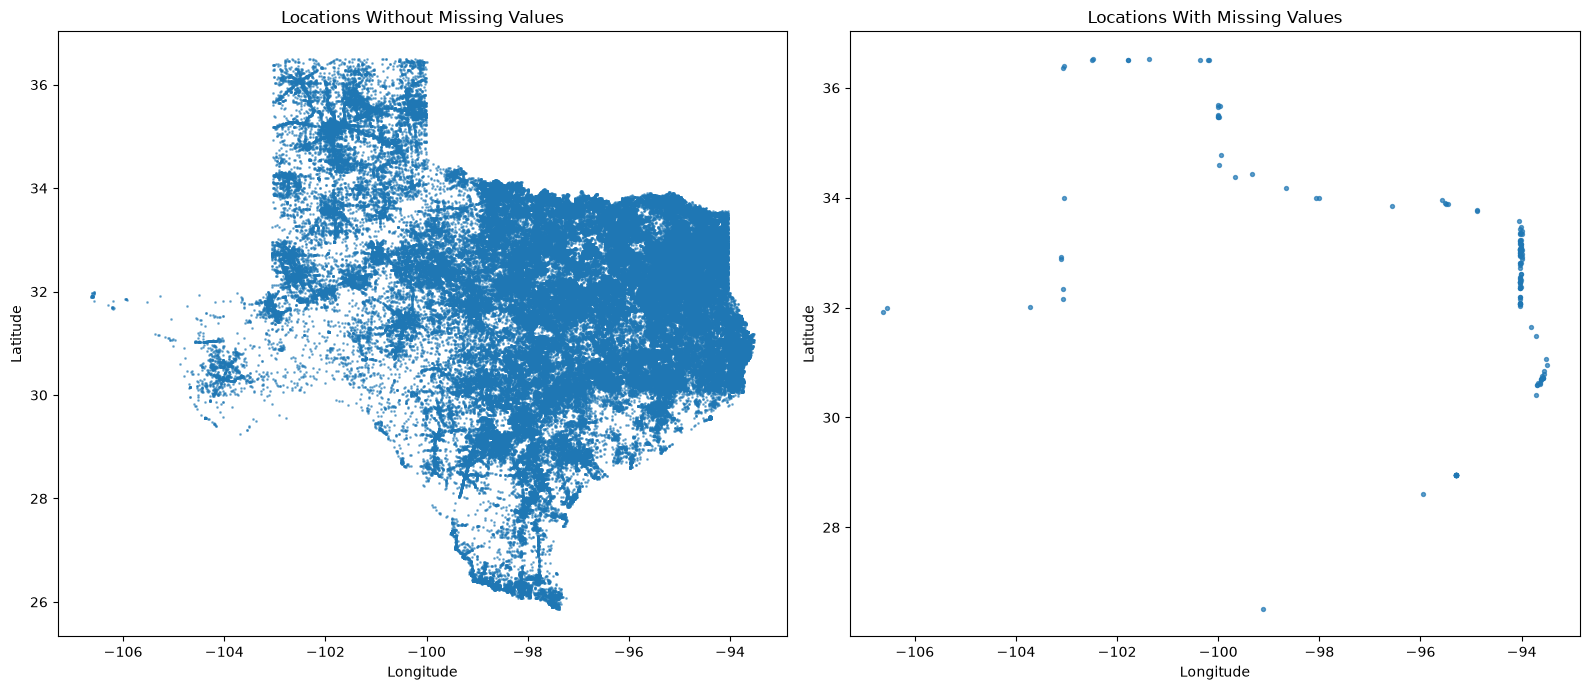

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Map 1: Locations with complete raster data
axes[0].scatter(
    complete_records["Long"],
    complete_records["Lat"],
    s=1,
    alpha=0.5
)

axes[0].set_title("Locations Without Missing Values")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

# Map 2: Locations missing values in 22 features
axes[1].scatter(
    missing_records["Long"],
    missing_records["Lat"],
    s=8,
    alpha=0.7
)

axes[1].set_title("Locations With Missing Values")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

Used coordinates to find underlying reason for the missing values. Figured out that the locations with missing values sat outside the Texas state boundary.

In [36]:
missing_locations = missing_records[["Lat", "Long"]].copy()

missing_locations

,Lat,Long
1020,32.361010,-94.025810
2675,36.509636,-100.175743
4750,32.185412,-94.037111
9305,32.888237,-103.104286
11643,28.944414,-95.288826
...,...,...
268590,32.990000,-94.023889
269768,33.752500,-94.874722
270036,32.992222,-94.035833
270895,33.153056,-94.030833


In [37]:
missing_locations.to_csv("missing_locations.csv", index=False)